# Acme Sports: trend analysis (100 weeks)

Five analyses required by the specification (section 7), run on all **100 weekly MRP runs** (Aug 2025 to Jun 2027),
as agreed with the client in the Week 2 review. Each analysis ends with how it connects to a buy-plan rule.

*Note:* factory utilisation in analyses 2 and 3 comes from `fact_factory_utilization` as delivered. The client is
reviewing records above 100%; the planning engine itself uses a rolling ledger built from its own assignments.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from engine.data_loader import load_data

plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False})
d = load_data()
pr = d.prs.merge(d.runs[["run_id", "week_number"]], on="run_id")
so, fu, cust = d.sales_orders, d.utilization.copy(), d.customers.set_index("customer_id")
art = d.articles.set_index("article_id")
print(f"{len(pr):,} requisitions · {pr['requested_qty'].sum():,.0f} units · {len(so):,} sales orders · "
      f"{pr['week_number'].nunique()} weeks")

24,962 requisitions · 17,175,451 units · 17,669 sales orders · 100 weeks


## 1. Seasonal demand curve

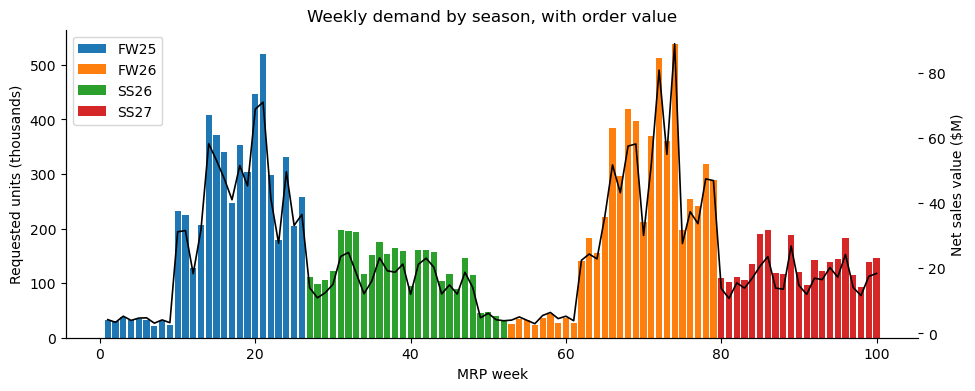

Units by calendar month (all years):
mrp_run_date
1     2274
2      869
3     1498
4     1174
5     1410
6      959
7      161
8      318
9      242
10    1491
11    3430
12    3350

Peak-to-trough ratio per market (4-week rolling average):
market_destination
CL    20.5
MX    20.5
BR    19.5
CO    18.3
AR    17.7
PE    16.3
US    16.1


In [2]:
weekly = pr.groupby(["week_number", "season"]).agg(units=("requested_qty", "sum")).reset_index()
nsv = so.merge(pr[["pr_id", "week_number"]], on="pr_id").groupby("week_number")["net_sales_value"].sum()

fig, ax = plt.subplots()
for season, g in weekly.groupby("season"):
    ax.bar(g["week_number"], g["units"] / 1e3, label=season)
ax2 = ax.twinx()
ax2.plot(nsv.index, nsv.values / 1e6, color="black", lw=1.2, label="NSV ($M)")
ax.set(xlabel="MRP week", ylabel="Requested units (thousands)", title="Weekly demand by season, with order value")
ax2.set_ylabel("Net sales value ($M)")
ax.legend(loc="upper left"); plt.show()

by_month = pr.groupby(pr["mrp_run_date"].dt.month)["requested_qty"].sum()
print("Units by calendar month (all years):"); print((by_month / 1e3).round(0).astype(int).to_string())

market = pr.groupby(["market_destination", "week_number"])["requested_qty"].sum().unstack(0).fillna(0)
rolling = market.rolling(4, center=True, min_periods=2).mean()
ratio = (rolling.max() / rolling.min()).round(1).sort_values(ascending=False)
print("\nPeak-to-trough ratio per market (4-week rolling average):"); print(ratio.to_string())

**What it shows.** Demand is strongly seasonal. Fall/Winter seasons carry about 5.3M to 5.8M units against
2.8M to 3.3M for Spring/Summer, and requisitions peak in **November to January** (Nov and Dec each above 3.3M units)
with a deep **July to September trough** (July about 0.16M). Every market swings 16× to 21× between its peak and trough;
Chile and Mexico swing the most.

**Rule connection.** Peak months concentrate demand into the same buying windows, which is when factories hit the
85% routing threshold (analysis 2). This justifies **pulling Fall/Winter demand into the quieter Aug–Oct windows**
(spec 3.3) instead of waiting for Rule 1 to make it due in the peak.

## 2. Factory utilisation and backup trigger frequency

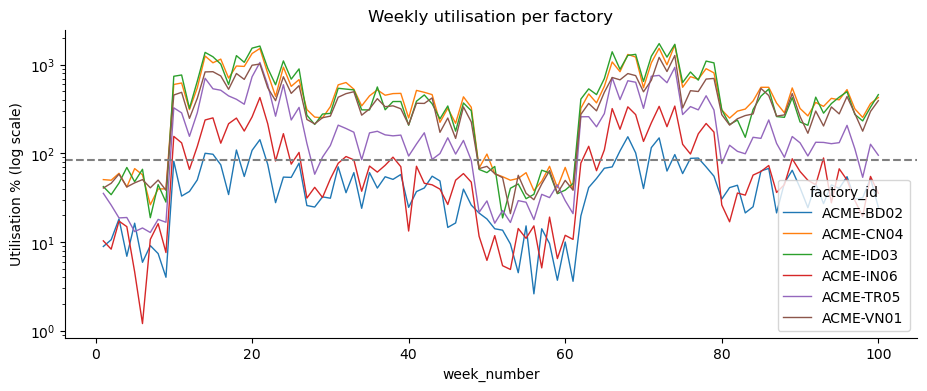

Weeks at or above 85%, by factory and season (share of weeks):
season      FW25  FW26  SS26  SS27
factory_id                        
ACME-BD02   0.19  0.30  0.00   0.0
ACME-CN04   0.65  0.67  0.88   1.0
ACME-ID03   0.65  0.67  0.85   1.0
ACME-IN06   0.54  0.59  0.08   0.1
ACME-TR05   0.65  0.67  0.73   0.9
ACME-VN01   0.65  0.67  0.85   1.0

Total overloaded weeks: {'ACME-BD02': 13, 'ACME-CN04': 79, 'ACME-ID03': 78, 'ACME-IN06': 34, 'ACME-TR05': 73, 'ACME-VN01': 78}

Correlation of weekly backup rate with utilisation: 0.82
Average backup rate in overloaded vs normal weeks: {False: 0.0, True: 0.62}


In [3]:
fu["overloaded"] = fu["utilization_pct"] >= 85
pivot = fu.pivot(index="week_number", columns="factory_id", values="utilization_pct")
ax = pivot.plot(logy=True, lw=1)
ax.axhline(85, ls="--", color="grey"); ax.set(ylabel="Utilisation % (log scale)", title="Weekly utilisation per factory")
plt.show()

print("Weeks at or above 85%, by factory and season (share of weeks):")
print(fu.pivot_table(index="factory_id", columns="season", values="overloaded", aggfunc="mean").round(2).to_string())
print("\nTotal overloaded weeks:", fu.groupby("factory_id")["overloaded"].sum().to_dict())

backup = (pr.groupby(["run_id", "primary_factory"])["backup_triggered"].mean().rename("backup_rate").reset_index()
          .merge(fu, left_on=["run_id", "primary_factory"], right_on=["run_id", "factory_id"]))
print(f"\nCorrelation of weekly backup rate with utilisation: {backup['backup_rate'].corr(backup['utilization_pct']):.2f}")
print("Average backup rate in overloaded vs normal weeks:", backup.groupby("overloaded")["backup_rate"].mean().round(2).to_dict())

**What it shows.** Three factories, **CN04, ID03 and VN01, are at or above 85% in 78 to 79 of the 100 weeks**,
and in SS27 they are overloaded every week. TR05 follows with 73 weeks, IN06 34 and BD02 only 13. The backup rule
fires as designed: backup rate correlates 0.82 with utilisation, about 62% of requisitions are rerouted in
overloaded weeks and none otherwise.

**Rule connection.** The backups form a loop (VN01 → ID03 → CN04 → VN01), and all three members are overloaded in the
same weeks. Routing to the backup at 85% (spec 3.2) therefore moves overload around the loop rather than relieving it.
BD02 and IN06 have spare capacity but are only certified for apparel. This supports **capacity-driven pull-forward**
over pure backup routing, and is the main motivation for planning factories together.

## 3. Pull-forward opportunity map

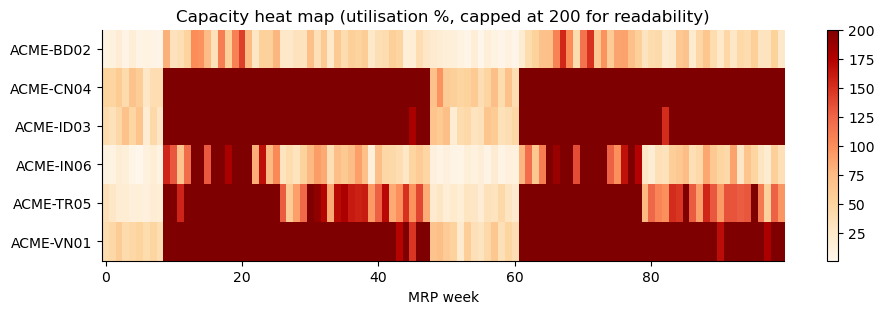

           overloaded_weeks  with_earlier_week  pullable_units
factory                                                       
ACME-BD02                13                 13         67761.0
ACME-CN04                79                 79        712879.0
ACME-ID03                78                 78        449124.0
ACME-IN06                34                 34        382623.0
ACME-TR05                73                 73        525937.0
ACME-VN01                78                 78        654615.0

Total pullable units: 2,792,939

Share of article-market lots in overloaded weeks that are below MOQ 300: 17%
market_destination
AR    0.19
BR    0.14
CL    0.18
CO    0.16
MX    0.14
PE    0.22
US    0.19


In [4]:
fig, ax = plt.subplots(figsize=(11, 3))
im = ax.imshow(pivot.T.clip(upper=200), aspect="auto", cmap="OrRd")
ax.set_yticks(range(len(pivot.columns)), pivot.columns); ax.set_xlabel("MRP week")
ax.set_title("Capacity heat map (utilisation %, capped at 200 for readability)")
fig.colorbar(im, ax=ax); plt.show()

rows = []
for f, g in fu.sort_values("week_number").groupby("factory_id"):
    for _, r in g[g["overloaded"]].iterrows():
        earlier = g[(g["week_number"] < r["week_number"]) & (g["utilization_pct"] < 60)]
        if earlier.empty:
            rows.append((f, r["week_number"], None, 0.0)); continue
        e = earlier.iloc[-1]
        excess = r["units_consumed"] - 0.85 * r["weekly_capacity"]
        room = 0.85 * e["weekly_capacity"] - e["units_consumed"]
        rows.append((f, r["week_number"], e["week_number"], max(0.0, min(excess, room))))
opp = pd.DataFrame(rows, columns=["factory", "overloaded_week", "nearest_week_below_60", "pullable_units"])
summary = opp.groupby("factory").agg(overloaded_weeks=("overloaded_week", "size"),
                                     with_earlier_week=("nearest_week_below_60", lambda s: s.notna().sum()),
                                     pullable_units=("pullable_units", "sum"))
print(summary.round(0).to_string()); print(f"\nTotal pullable units: {opp['pullable_units'].sum():,.0f}")

x = pr.merge(fu[["run_id", "factory_id", "overloaded"]], left_on=["run_id", "assigned_factory"],
             right_on=["run_id", "factory_id"])
lots = x[x["overloaded"]].groupby(["run_id", "article_id", "market_destination"])["requested_qty"].sum()
by_market = (lots < 300).groupby(level="market_destination").mean().round(2)
print(f"\nShare of article-market lots in overloaded weeks that are below MOQ 300: {(lots < 300).mean():.0%}")
print(by_market.to_string())

**What it shows.** Every one of the 355 overloaded factory-weeks has an **earlier week below 60%** at the same
factory. Moving the excess above 85% into the nearest such week, limited by that week's headroom, could shift about
**2.8M units**; CN04 and VN01 account for the largest share. About 17% of article-market lots in overloaded weeks are
below the 300-unit MOQ on their own.

**Rule connection.** Spec 3.3 requires pull-forward to be validated **per market** (one market's demand cannot fill
another's MOQ), and Rule 4 piggyback only auto-triggers within 5% of a threshold. Because a sixth of overloaded lots
are small, pull-forward recommendations must check each market's MOQ, which the engine's pull-forward analysis does.

## 4. Forecast vs firm coverage (wholesale)

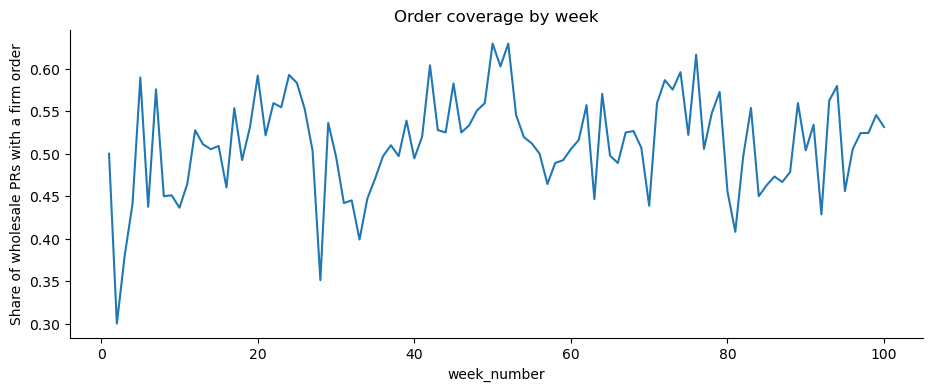

Coverage by range version: {'V1': 0.467, 'V2': 0.507, 'V3': 0.563}
Estimated NSV of forecast-only wholesale demand by season ($M):
season
FW25    335.7
FW26    327.3
SS26    177.6
SS27    153.7


In [5]:
ws = pr[pr["channel_id"] == "01"].copy()
ws["covered"] = ws["pr_id"].isin(so["pr_id"])
weekly_cov = ws.groupby("week_number")["covered"].mean()
ax = weekly_cov.plot(); ax.set(ylabel="Share of wholesale PRs with a firm order", title="Order coverage by week")
plt.show()
print("Coverage by range version:", ws.groupby("range_version")["covered"].mean().round(3).to_dict())

ordered = so.merge(pr[["pr_id", "article_id", "requested_qty"]], on="pr_id").groupby("article_id")
nsv_per_unit = ordered["net_sales_value"].sum() / ordered["requested_qty"].sum()
ws["est_nsv"] = ws["requested_qty"] * ws["article_id"].map(nsv_per_unit)
risk = ws[~ws["covered"]].groupby("season")["est_nsv"].sum() / 1e6
print("Estimated NSV of forecast-only wholesale demand by season ($M):"); print(risk.round(1).to_string())

**What it shows.** About half of wholesale requisitions have a firm order. Coverage improves through the range
stages: **46.7% at V1, 50.7% at V2, 56.3% at V3**. Forecast-only demand has no sales order and therefore no NSV, so we
estimate it from each article's average NSV per ordered unit: roughly **$336M (FW25), $327M (FW26), $178M (SS26)
and $154M (SS27)** of value sits in forecast-only demand.

**Rule connection.** Rule 5 moves this demand to Future. Planners should expect the **most exclusions at V1**, early
in each season, and the value at stake is large enough that early-buy exceptions deserve explicit review.

## 5. NSV at risk by market and credit rating

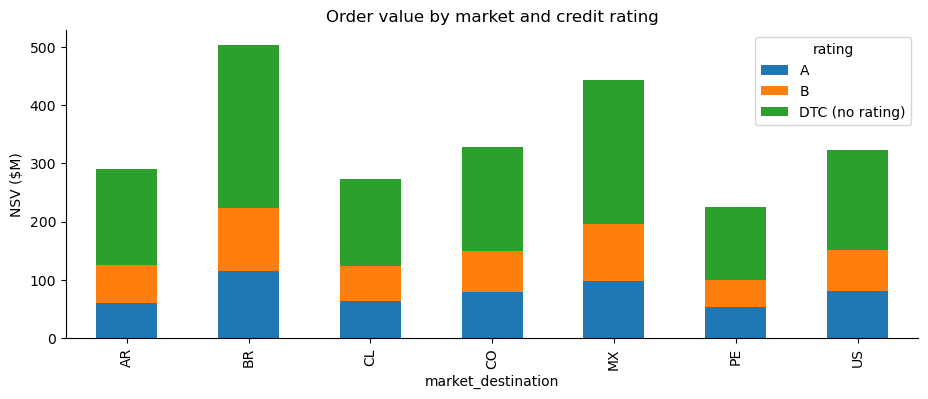

rating                  A      B  DTC (no rating)
market_destination                               
AR                   59.5   66.8            163.7
BR                  114.5  109.0            280.2
CL                   63.6   59.5            150.2
CO                   78.8   71.2            177.9
MX                   97.9   97.4            247.9
PE                   52.8   46.5            125.4
US                   81.0   69.9            171.8

Share of NSV by rating: {'A': 0.23, 'B': 0.218, 'DTC (no rating)': 0.552}
C-rated customers: ['CUST-0001', 'CUST-0021', 'CUST-0047'] · their orders: 0

Highest B-rated exposure (market, quarter), $M:
market_destination  quarter
BR                  Q4         54.0
MX                  Q4         52.4
AR                  Q4         34.6
CO                  Q4         33.6
US                  Q4         33.3


In [6]:
y = so.merge(pr[["pr_id", "market_destination"]], on="pr_id")
y["rating"] = y["customer_id"].map(cust["credit_rating"]).fillna("DTC (no rating)")
table = y.pivot_table(index="market_destination", columns="rating", values="net_sales_value", aggfunc="sum").fillna(0) / 1e6
ax = table.plot(kind="bar", stacked=True); ax.set(ylabel="NSV ($M)", title="Order value by market and credit rating")
plt.show()
print(table.round(1).to_string())
print("\nShare of NSV by rating:", (y.groupby("rating")["net_sales_value"].sum() / y["net_sales_value"].sum()).round(3).to_dict())
print("C-rated customers:", list(cust.index[cust["credit_rating"] == "C"]),
      "· their orders:", int(y["customer_id"].isin(cust.index[cust["credit_rating"] == "C"]).sum()))
b = y[y["rating"] == "B"].groupby(["market_destination", "quarter"])["net_sales_value"].sum().sort_values(ascending=False) / 1e6
print("\nHighest B-rated exposure (market, quarter), $M:"); print(b.head(5).round(1).to_string())

**What it shows.** Total order value is **$2.39B**. Direct-to-consumer orders (treated as one customer, per the
client) are about 55% of it and carry no credit rating; A-rated and B-rated wholesale customers each hold roughly
23% and 22%. **The three C-rated customers have no orders**, so C-rated exposure is $0 in this dataset (raised with the
client). Brazil carries the largest exposure in every rating group, and B-rated exposure peaks in **Q4**
(Brazil about $54M, Mexico about $52M). Market here is the requisition's destination;
for 87% of wholesale orders it differs from the customer's home market.

**Rule connection.** This feeds the **credit-hold what-if scenario**: holding a B-rated customer, or DTC as a single
customer, shows the NSV at risk and any lots that fall below MOQ. Because C exposure is zero, the hold scenario is
demonstrated with B-rated customers and DTC.